--- Alpha-Beta Pruning Visual Graph ---
Enter tree in single line: [[[5 6][7 4 5]][[3]]][[[6][6 9]][[7]]][[[5]][[9 8][6]]]
Is Root MAX or MIN? (max/min) [default: max]: max

Optimal Value : 6
Pruned Leaves : [5, 9, 9, 8, 6]


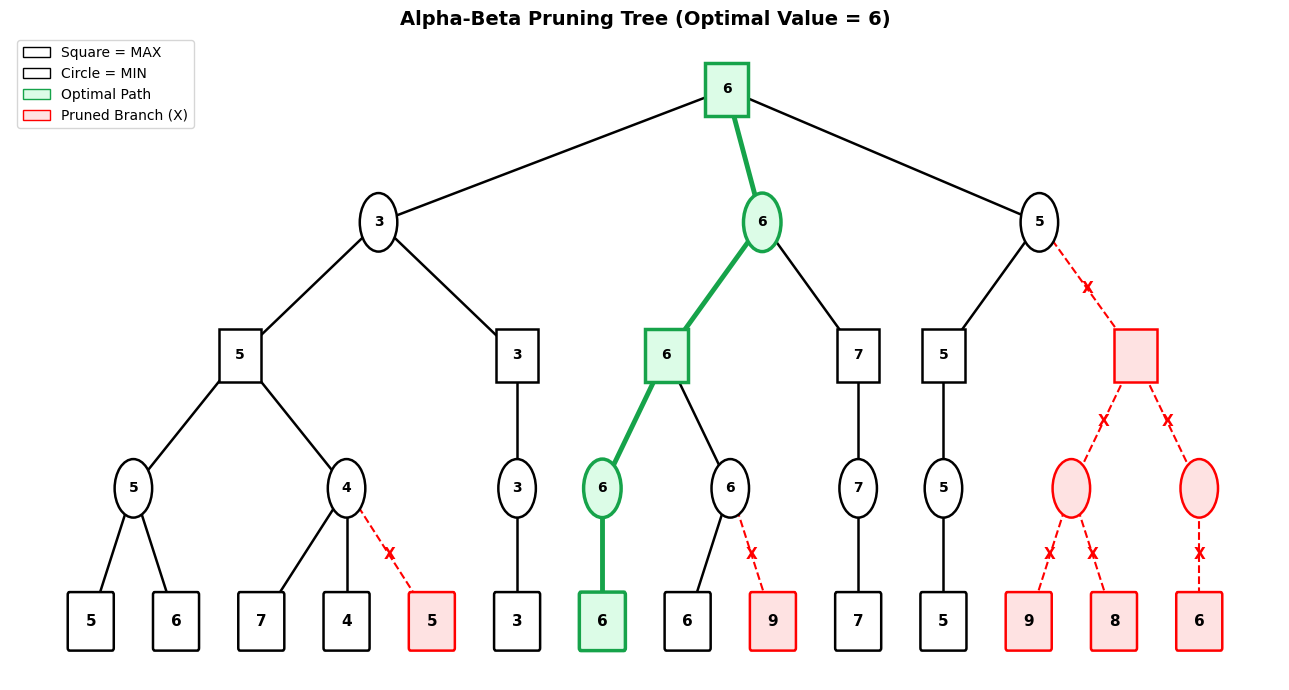

In [2]:
import math
import matplotlib.patches as patches
import matplotlib.pyplot as plt


def parse_tree_from_string(raw_text):
    raw_text = raw_text.strip()
    tokens = raw_text.replace("[", " [ ").replace("]", " ] ").split()

    root = {
        "name": "Root",
        "children": [],
        "val": None,
        "best_child": None,
        "pruned": False,
    }
    stack = [root]

    for token in tokens:
        if token == "[":
            node = {
                "name": "",
                "children": [],
                "val": None,
                "best_child": None,
                "pruned": False,
            }
            stack[-1]["children"].append(node)
            stack.append(node)
        elif token == "]":
            finished = stack.pop()
            # Remove empty bracket nodes if any exist
            if not finished["children"] and finished["val"] is None:
                stack[-1]["children"].remove(finished)
        else:
            leaf_val = int(token)
            node = {
                "name": str(leaf_val),
                "children": [],
                "val": leaf_val,
                "best_child": None,
                "pruned": False,
            }
            stack[-1]["children"].append(node)

    if len(root["children"]) == 1 and root["children"][0]["children"]:
        return root["children"][0]
    return root


def mark_pruned(node):
    node["pruned"] = True
    for child in node["children"]:
        mark_pruned(child)


def collect_leaves(node, out):
    if not node["children"]:
        out.append(node["val"])
    for child in node["children"]:
        collect_leaves(child, out)


def alpha_beta(node, is_max, alpha, beta, pruned_leaves):
    if not node["children"]:
        return node["val"]

    if is_max:
        best = -math.inf
        for i, child in enumerate(node["children"]):
            val = alpha_beta(child, False, alpha, beta, pruned_leaves)
            if val > best:
                best = val
                node["best_child"] = i
            alpha = max(alpha, best)

            if beta <= alpha:
                for skipped in node["children"][i + 1 :]:
                    mark_pruned(skipped)
                    collect_leaves(skipped, pruned_leaves)
                break
        node["val"] = best
        return best
    else:
        best = math.inf
        for i, child in enumerate(node["children"]):
            val = alpha_beta(child, True, alpha, beta, pruned_leaves)
            if val < best:
                best = val
                node["best_child"] = i
            beta = min(beta, best)

            if beta <= alpha:
                for skipped in node["children"][i + 1 :]:
                    mark_pruned(skipped)
                    collect_leaves(skipped, pruned_leaves)
                break
        node["val"] = best
        return best


def assign_positions(node, depth=0, counter=None):
    if counter is None:
        counter = [0]

    node["y"] = -depth
    if not node["children"]:
        node["x"] = counter[0]
        counter[0] += 1
    else:
        for child in node["children"]:
            assign_positions(child, depth + 1, counter)
        node["x"] = sum(c["x"] for c in node["children"]) / len(
            node["children"]
        )


def draw_graph(root, is_root_max):
    assign_positions(root)
    fig, ax = plt.subplots(figsize=(13, 7))
    ax.axis("off")

    def draw_edges(node, on_best_path=True):
        for i, child in enumerate(node["children"]):
            is_best = (
                on_best_path
                and (node["best_child"] == i)
                and not child["pruned"]
            )
            if child["pruned"]:
                ax.plot(
                    [node["x"], child["x"]],
                    [node["y"], child["y"]],
                    color="red",
                    linestyle="--",
                    linewidth=1.5,
                    zorder=1,
                )
                mid_x, mid_y = (node["x"] + child["x"]) / 2, (
                    node["y"] + child["y"]
                ) / 2
                ax.text(
                    mid_x,
                    mid_y,
                    "X",
                    color="red",
                    fontsize=11,
                    fontweight="bold",
                    ha="center",
                    va="center",
                    zorder=4,
                )
            elif is_best:
                ax.plot(
                    [node["x"], child["x"]],
                    [node["y"], child["y"]],
                    color="#16a34a",
                    linewidth=3.5,
                    zorder=2,
                )
            else:
                ax.plot(
                    [node["x"], child["x"]],
                    [node["y"], child["y"]],
                    color="black",
                    linewidth=1.8,
                    zorder=1,
                )

            draw_edges(child, is_best)

    def draw_nodes(node, is_max, on_best_path=True):
        x, y = node["x"], node["y"]
        edge_color = (
            "#16a34a"
            if (on_best_path and not node["pruned"])
            else ("red" if node["pruned"] else "black")
        )
        face_color = (
            "#dcfce7"
            if (on_best_path and not node["pruned"])
            else ("#fee2e2" if node["pruned"] else "white")
        )
        lw = 2.5 if on_best_path else 1.8

        if not node["children"]:
            box = patches.FancyBboxPatch(
                (x - 0.25, y - 0.2),
                0.5,
                0.4,
                boxstyle="round,pad=0.02",
                facecolor=face_color,
                edgecolor=edge_color,
                linewidth=lw,
                zorder=3,
            )
            ax.add_patch(box)
            ax.text(
                x,
                y,
                str(node["val"]),
                fontsize=11,
                fontweight="bold",
                ha="center",
                va="center",
                zorder=4,
            )
        elif is_max:
            sq = patches.Rectangle(
                (x - 0.25, y - 0.2),
                0.5,
                0.4,
                facecolor=face_color,
                edgecolor=edge_color,
                linewidth=lw,
                zorder=3,
            )
            ax.add_patch(sq)
            if node["val"] is not None:
                ax.text(
                    x,
                    y,
                    str(node["val"]),
                    fontsize=10,
                    fontweight="bold",
                    ha="center",
                    va="center",
                    zorder=4,
                )
        else:
            circ = patches.Circle(
                (x, y),
                0.22,
                facecolor=face_color,
                edgecolor=edge_color,
                linewidth=lw,
                zorder=3,
            )
            ax.add_patch(circ)
            if node["val"] is not None:
                ax.text(
                    x,
                    y,
                    str(node["val"]),
                    fontsize=10,
                    fontweight="bold",
                    ha="center",
                    va="center",
                    zorder=4,
                )

        for i, child in enumerate(node["children"]):
            is_best = (
                on_best_path
                and (node["best_child"] == i)
                and not child["pruned"]
            )
            draw_nodes(child, not is_max, is_best)

    draw_edges(root, True)
    draw_nodes(root, is_root_max, True)

    legend_elements = [
        patches.Patch(
            facecolor="white", edgecolor="black", label="Square = MAX"
        ),
        patches.Patch(
            facecolor="white", edgecolor="black", label="Circle = MIN"
        ),
        patches.Patch(
            facecolor="#dcfce7", edgecolor="#16a34a", label="Optimal Path"
        ),
        patches.Patch(
            facecolor="#fee2e2", edgecolor="red", label="Pruned Branch (X)"
        ),
    ]
    ax.legend(
        handles=legend_elements, loc="upper left", frameon=True, fontsize=10
    )
    plt.title(
        f"Alpha-Beta Pruning Tree (Optimal Value = {root['val']})",
        fontsize=14,
        fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


def main():
    print("--- Alpha-Beta Pruning Visual Graph ---")
    raw_tree = input("Enter tree in single line: ")
    tree = parse_tree_from_string(raw_tree)

    turn = (
        input("Is Root MAX or MIN? (max/min) [default: max]: ").strip().lower()
    )
    is_max = False if turn == "min" else True

    pruned_leaves = []
    optimal_value = alpha_beta(tree, is_max, -math.inf, math.inf, pruned_leaves)

    print(f"\nOptimal Value : {optimal_value}")
    print(f"Pruned Leaves : {pruned_leaves if pruned_leaves else 'None'}")

    draw_graph(tree, is_max)


if __name__ == "__main__":
    main()

